# Analisis Klaster Gempa (K-Means + Silhouette)
**Tujuan:**
1. Melakukan klastering gempa menggunakan K-Means.
2. Menentukan jumlah klaster *k* terbaik menggunakan *silhouette score*.
3. Menandai tingkat keparahan klaster berdasarkan *magnitude* dan kedalaman.
4. Menyimpan model untuk dipakai di aplikasi Streamlit.

**Input:** `data/raw/katalog_gempa_v2.tsv` (katalog gempa BMKG).

Logika training ada di paket `src/gempa/` dan dipakai juga oleh CLI `python -m gempa.train`,
sehingga hasil notebook ini sama persis dengan artifact yang dipakai aplikasi.

**Output:**
- `models/kmeans_pipeline.joblib` (pipeline MinMaxScaler + KMeans),
- `models/cluster_info.csv` (rata-rata fitur, severity & label tiap klaster),
- `models/metadata.json` (parameter, metrik, mapping label, versi library),
- `data/processed/earthquakes_with_cluster.parquet` (data gempa + label klaster).

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score
from sklearn.preprocessing import MinMaxScaler, RobustScaler

# Notebook ada di notebooks/, paket gempa ada di ../src
sys.path.insert(0, str(Path.cwd().parent / "src"))

from gempa import paths
from gempa.train import (FEATURES, RANDOM_STATE, SILHOUETTE_SAMPLE, prepare_events, save_artifacts, scan_k,
                         silhouette, train)

print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.1 | pandas 3.1.1


In [2]:
# Katalog bersih (Mw, Mc, declustering, intensitas; lihat data_cleaning.ipynb).
# K-Means tetap memakai magnitudo & kedalaman asli dari katalog.
df = prepare_events(paths.RAW_CATALOG)
print(f"Loaded {len(df):,} earthquake records")
df[["eventID", "time", "latitude", "longitude", "mag", "mag_type", "depth", "mw", "mmi_class"]].head()

Loaded 131,131 earthquake records


,eventID,time,latitude,longitude,mag,mag_type,depth,mw,mmi_class
0,bmg2008vkye,2008-11-01 00:31:25.143741+00:00,-0.604440,98.895531,2.989742,MLv,20,3.270557,III-IV
1,bmg2008vlag,2008-11-01 01:34:29.660856+00:00,-6.611860,129.387220,5.507549,mb,30,5.379103,V-VI
2,bmg2008vlaj,2008-11-01 01:38:14.802129+00:00,-3.650586,127.990680,3.539674,MLv,5,3.674922,V-VI
3,bmg2008vlbt,2008-11-01 02:20:05.909515+00:00,-4.198925,128.097000,2.424314,MLv,5,2.854798,V-VI
4,bmg2008vlcd,2008-11-01 02:32:18.756155+00:00,-4.091891,128.200470,2.410045,MLv,10,2.844306,III-IV


In [3]:
df[["latitude", "longitude", "mag", "depth"]].describe()

,latitude,longitude,mag,depth
count,131131.000000,131131.000000,131131.000000,131131.000000
mean,-3.355595,119.280062,3.512964,49.661964
std,4.329033,10.745900,0.830521,79.716301
min,-11.231423,95.002388,0.191153,0.000000
25%,-7.831254,113.469246,2.908710,10.000000
50%,-2.840024,121.198982,3.452434,16.000000
75%,0.152819,126.837856,4.092975,54.000000
max,5.999397,140.998291,7.902198,750.000000


Features used for clustering (Risk Profiling Only): ['mag', 'depth']
Total data points used: 131131

--- 📊 Statistik Data Feature ---


,count,mean,std,min,25%,50%,75%,max
mag,131131.0,3.512964,0.830521,0.191153,2.90871,3.452434,4.092975,7.902198
depth,131131.0,49.661964,79.716301,0.000000,10.00000,16.000000,54.000000,750.000000



--- 🌍 Distribusi Awal Risiko (Magnitude vs Depth) ---


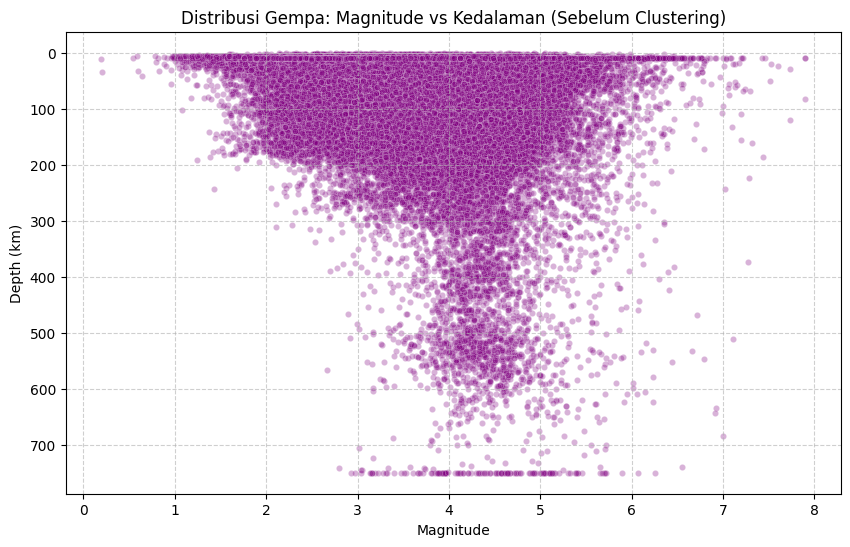

In [4]:
# Fitur fisik SAJA untuk clustering risiko: Magnitude dan Depth.
# Latitude dan Longitude tidak dipakai agar klaster tidak terbentuk karena lokasi geografis.
X = df[FEATURES].copy()

print("Features used for clustering (Risk Profiling Only):", FEATURES)
print("Total data points used:", len(X))

print("\n--- 📊 Statistik Data Feature ---")
display(X.describe().T)

print("\n--- 🌍 Distribusi Awal Risiko (Magnitude vs Depth) ---")
plt.figure(figsize=(10, 6))
sns.scatterplot(data=X, x='mag', y='depth', alpha=0.3, color='purple', s=20)
plt.title('Distribusi Gempa: Magnitude vs Kedalaman (Sebelum Clustering)')
plt.xlabel('Magnitude')
plt.ylabel('Depth (km)')
plt.gca().invert_yaxis()  # Kedalaman makin besar makin ke bawah grafiknya
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Mencari jumlah klaster terbaik (k)...


,k,inertia,silhouette
0,2,1868.871071,0.448033
1,3,1147.060688,0.459057
2,4,831.754772,0.472402
3,5,611.662551,0.425894
4,6,504.823297,0.443222
5,7,420.243729,0.417279


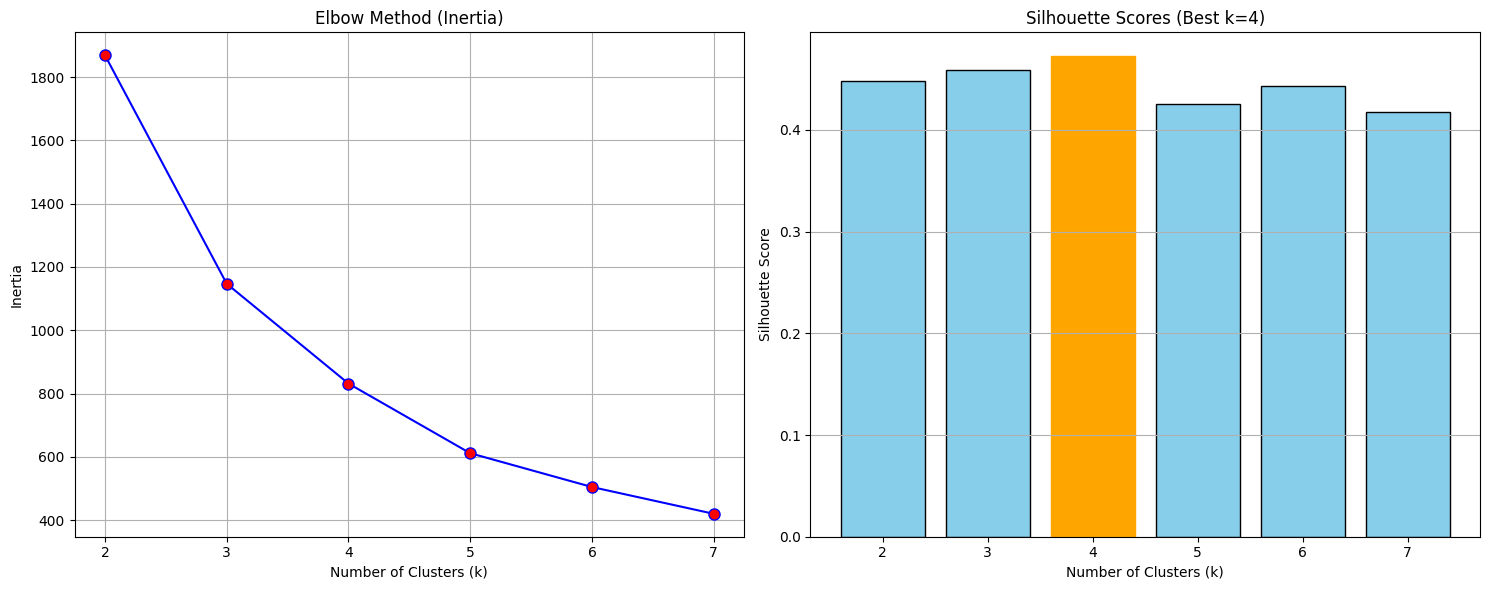


✅ Best k detected: 4 (Silhouette Score: 0.4724)


In [5]:
# Pencarian k: inertia (elbow) + silhouette.
# Silhouette dihitung pada sampel acak 20.000 titik (seed tetap) karena kompleksitasnya O(n^2);
# sampel yang sama dipakai lagi untuk evaluasi akhir agar angkanya konsisten.
print("Mencari jumlah klaster terbaik (k)...")
k_scan = scan_k(X)
best_idx = k_scan["silhouette"].idxmax()
best_k = int(k_scan.loc[best_idx, "k"])
display(k_scan)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Elbow Method (Inertia)
ax1.plot(k_scan["k"], k_scan["inertia"], 'bo-', markerfacecolor='red', markersize=8)
ax1.set_title('Elbow Method (Inertia)')
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia')
ax1.grid(True)

# Plot 2: Silhouette Score
bars = ax2.bar(k_scan["k"], k_scan["silhouette"], color='skyblue', edgecolor='black')
bars[best_idx].set_color('orange')  # Highlight best k
ax2.set_title(f'Silhouette Scores (Best k={best_k})')
ax2.set_xlabel('Number of Clusters (k)')
ax2.set_ylabel('Silhouette Score')
ax2.grid(axis='y')

plt.tight_layout()
plt.show()

print(f"\n✅ Best k detected: {best_k} (Silhouette Score: {k_scan.loc[best_idx, 'silhouette']:.4f})")

In [6]:
# --- FIT MODEL FINAL DENGAN BEST K ---
print(f"Fitting final KMeans model with k={best_k}...")
result = train(df, k=best_k, k_scan=k_scan)

# df kini memiliki kolom 'cluster' (ID mentah KMeans) dan 'label' (label risiko)
df = result.events
cluster_summary = result.summary
print("✅ Kolom 'cluster' dan 'label' ditambahkan ke df")

Fitting final KMeans model with k=4...


✅ Kolom 'cluster' dan 'label' ditambahkan ke df


In [7]:
# --- ANALISIS CENTROID & PELABELAN ---
# Rata-rata fitur tiap klaster dihitung dari data asli (bukan inverse_transform),
# sehingga lokasi rata-rata klaster tetap bisa dilaporkan walau tidak dipakai model.
# Severity = intensitas episentrum Gutenberg-Richter (1956) dari rata-rata mag & depth:
#   I0 = 1.5*M - 3.5*log10(h) + 3.0   (h minimum 5 km)
# Label diberikan berurutan dari severity terendah (Low) ke tertinggi (Very High).
display(cluster_summary)

print("Mapping ID klaster KMeans -> label risiko:")
for _, row in cluster_summary.iterrows():
    print(f"  Cluster {int(row['cluster'])} -> {row['label']:<9} | Mean Intensity (I0): {row['severity_score']:.2f}")

label_order = list(cluster_summary["label"])
print("\nJumlah event per label:")
print(df["label"].value_counts().reindex(label_order))

,cluster,mag,depth,latitude,longitude,severity_score,label
0,2,4.425576,490.910329,-3.503026,122.273943,0.219857,Low
1,3,3.992477,162.205891,-3.283368,122.030598,1.253482,Moderate
2,1,2.877401,24.993525,-3.761796,118.202373,2.423706,High
3,0,4.231916,25.136230,-2.778468,119.740573,4.446824,Very High


Mapping ID klaster KMeans -> label risiko:
  Cluster 2 -> Low       | Mean Intensity (I0): 0.22
  Cluster 3 -> Moderate  | Mean Intensity (I0): 1.25
  Cluster 1 -> High      | Mean Intensity (I0): 2.42
  Cluster 0 -> Very High | Mean Intensity (I0): 4.45

Jumlah event per label:
label
Low           2130
Moderate     16295
High         67026
Very High    45680
Name: count, dtype: int64


---
## 📚 PENJELASAN LOGIKA RISK CLUSTERING (REVISI SCIENTIFIC)

### 1. Fitur yang Digunakan
Kita menggunakan 2 fitur fisik utama:
- **Magnitude:** Kekuatan gempa.
- **Depth:** Kedalaman pusat gempa.

### 2. Gutenberg-Richter Epicentral Intensity ($I_0$)
Untuk menentukan label risiko (Low s/d Very High) secara ilmiah dan mencerminkan **kerusakan di permukaan**, kita menggunakan pendekatan **Intensitas Episentrum** berdasarkan hubungan empiris Gutenberg-Richter (1956):

$$ I_0 = 1.5 M - 3.5 \log_{10}(h) + 3.0 $$

- **$M$ (Magnitude):** Berkontribusi linear positif. Semakin besar M, semakin besar intensitas.
- **$h$ (Depth):** Berkontribusi logaritmik negatif. Semakin dalam gempa, intensitas di permukaan turun drastis (atenuasi).
- **Konstanta 3.0:** Faktor kalibrasi empiris.

**Kenapa ini Akurat?**
Rumus ini mengoreksi bias rumus linear sebelumnya. Gempa dalam (misal 300km) meskipun Magnitudonya besar, akan menghasilkan $I_0$ yang kecil karena faktor $-3.5 \log(300)$ yang signifikan (-8.6). Sebaliknya, gempa dangkal (10km) hanya dikurangi sedikit (-3.5), sehingga risikonya tetap tinggi.

---


RISK LEVEL   | CLUSTER ID |    COUNT | PERCENT
Low          |          2 |    2,130 |    1.6%
Moderate     |          3 |   16,295 |   12.4%
High         |          1 |   67,026 |   51.1%
Very High    |          0 |   45,680 |   34.8%
TOTAL                     |  131,131 | 100.0%


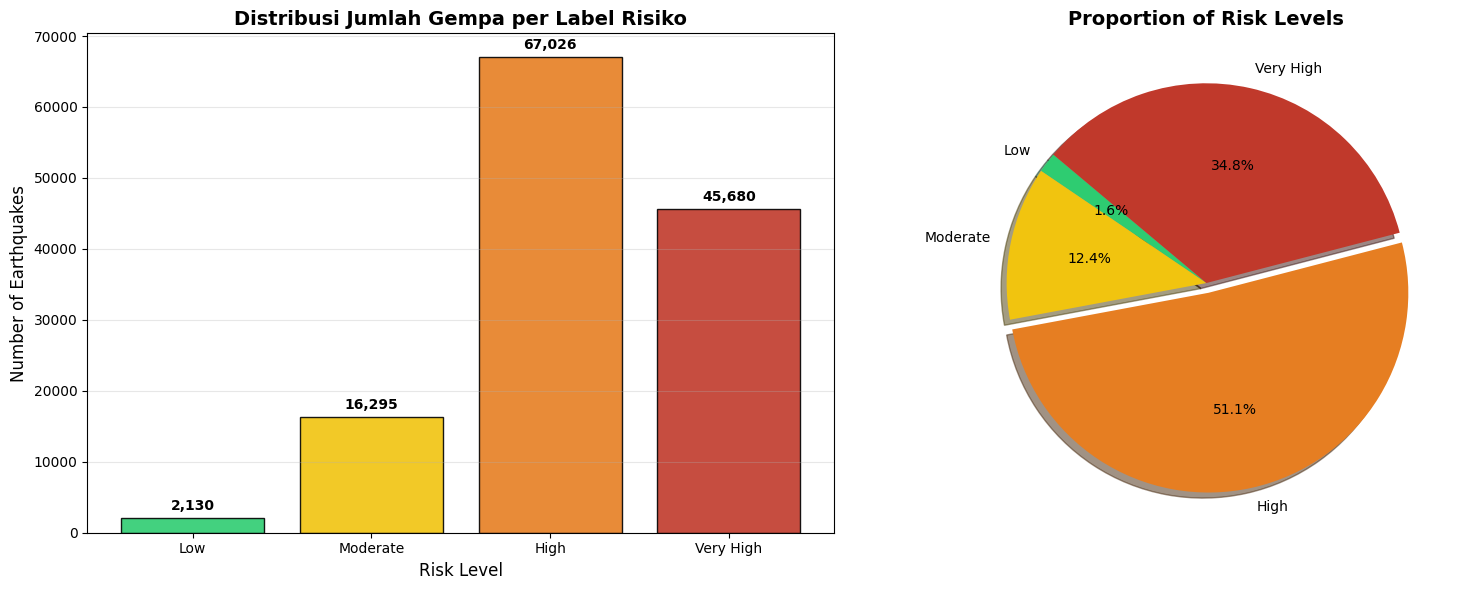

In [8]:
# Analisis Jumlah Anggota per Label Risiko (urut Low -> Very High)
# Catatan: ID klaster KMeans tidak berurutan sesuai risiko, jadi hitung berdasarkan kolom 'label'.
label_counts = df["label"].value_counts().reindex(label_order, fill_value=0)
cluster_of = dict(zip(cluster_summary["label"], cluster_summary["cluster"]))

colors = ['#2ecc71', '#f1c40f', '#e67e22', '#c0392b']  # Green -> Red
if len(label_order) != 4:
    colors = sns.color_palette("viridis", len(label_order))
color_map = dict(zip(label_order, colors))

total = len(df)
print("=" * 60)
print(f"{'RISK LEVEL':<12} | {'CLUSTER ID':>10} | {'COUNT':>8} | {'PERCENT':>7}")
print("=" * 60)
for lbl, count in label_counts.items():
    print(f"{lbl:<12} | {int(cluster_of[lbl]):>10} | {count:>8,d} | {count / total * 100:>6.1f}%")
print("=" * 60)
print(f"{'TOTAL':<25} | {total:>8,d} | 100.0%")
print("=" * 60)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Bar Chart
bars = axes[0].bar(label_order, label_counts.values, color=colors, edgecolor='black', alpha=0.9)
axes[0].set_xlabel('Risk Level', fontsize=12)
axes[0].set_ylabel('Number of Earthquakes', fontsize=12)
axes[0].set_title('Distribusi Jumlah Gempa per Label Risiko', fontsize=14, fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)
for bar, count in zip(bars, label_counts.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2., bar.get_height() + label_counts.max() * 0.01,
                 f'{count:,}', ha='center', va='bottom', fontweight='bold')

# 2. Pie Chart
explode = [0.05 if c == label_counts.max() else 0 for c in label_counts.values]
axes[1].pie(label_counts.values, labels=label_order, autopct='%1.1f%%', startangle=140,
            colors=colors, explode=explode, shadow=True)
axes[1].set_title('Proportion of Risk Levels', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

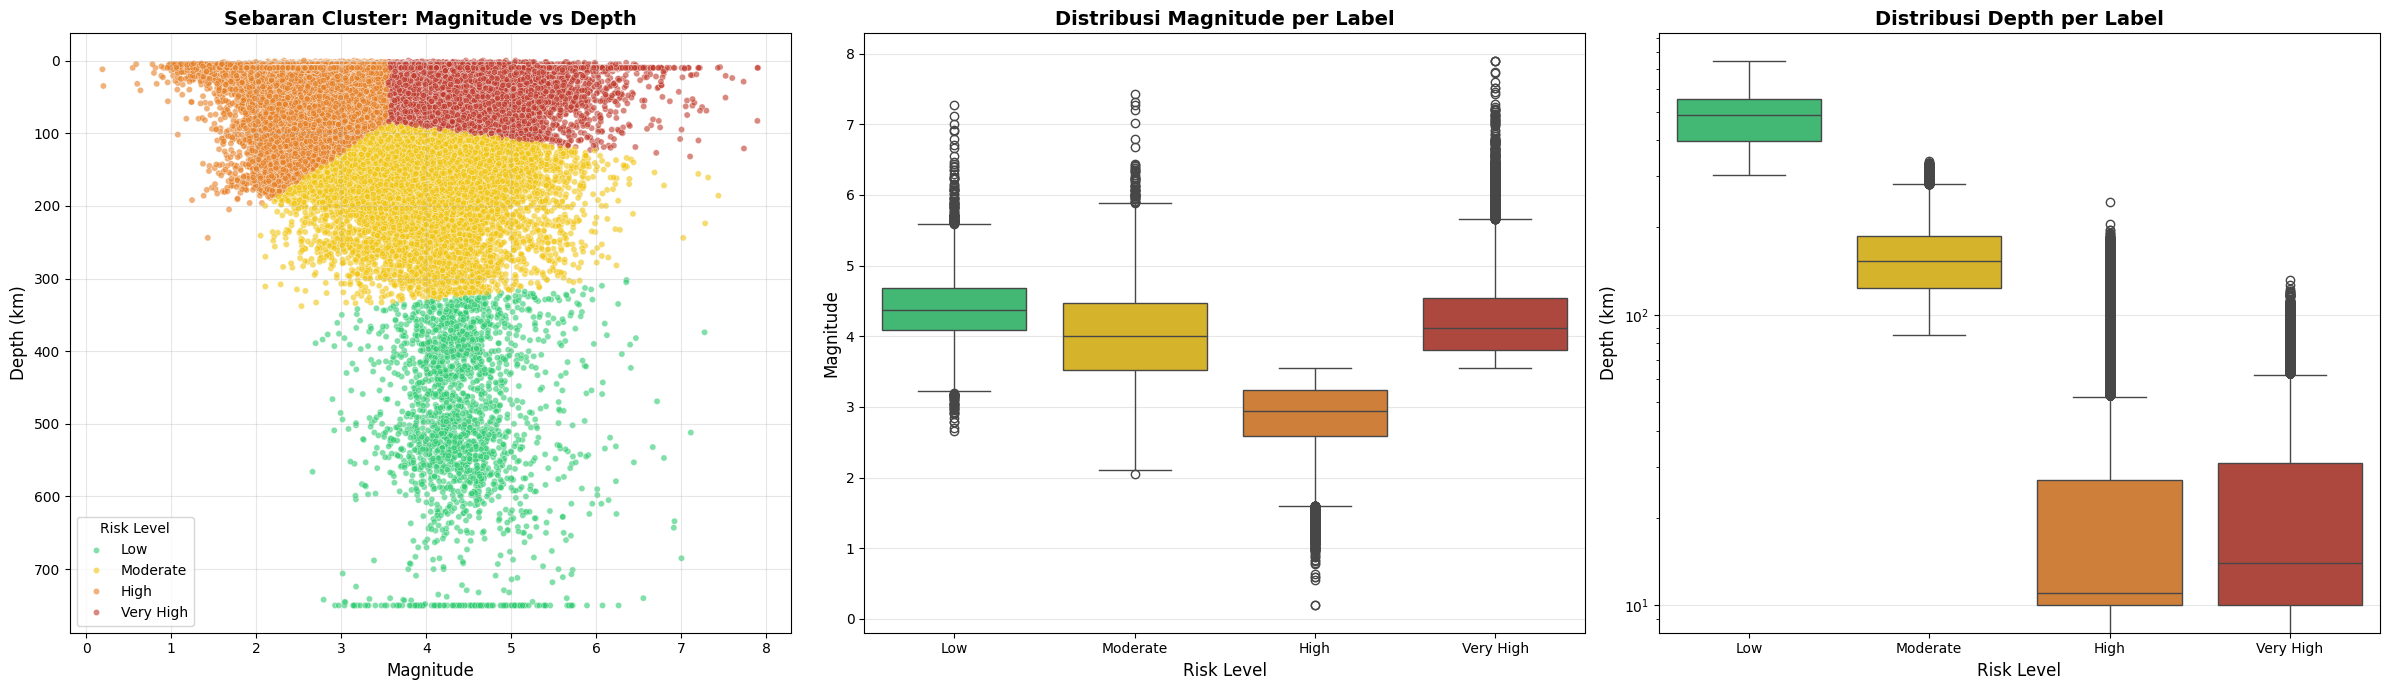

In [9]:
# --- DISTRIBUTION VISUALIZATION AFTER CLUSTERING ---
# Visualisasi Sebaran Data: Scatter Plot & Box Plot
fig, axes = plt.subplots(1, 3, figsize=(24, 7))

# 1. Scatter Plot: Magnitude vs Depth
sns.scatterplot(data=df, x='mag', y='depth', hue='label', palette=color_map, hue_order=label_order,
                ax=axes[0], alpha=0.6, s=20)
axes[0].set_title('Sebaran Cluster: Magnitude vs Depth', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Magnitude', fontsize=12)
axes[0].set_ylabel('Depth (km)', fontsize=12)
axes[0].invert_yaxis()  # Depth semakin dalam semakin ke bawah
axes[0].legend(title='Risk Level', loc='lower left')
axes[0].grid(True, alpha=0.3)

# 2. Box Plot: Distribusi Magnitude per Label
sns.boxplot(data=df, x='label', y='mag', hue='label', palette=color_map, order=label_order,
            legend=False, ax=axes[1])
axes[1].set_title('Distribusi Magnitude per Label', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Risk Level', fontsize=12)
axes[1].set_ylabel('Magnitude', fontsize=12)
axes[1].grid(axis='y', alpha=0.3)

# 3. Box Plot: Distribusi Depth per Label
sns.boxplot(data=df, x='label', y='depth', hue='label', palette=color_map, order=label_order,
            legend=False, ax=axes[2])
axes[2].set_title('Distribusi Depth per Label', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Risk Level', fontsize=12)
axes[2].set_ylabel('Depth (km)', fontsize=12)
axes[2].set_yscale('log')  # Log scale untuk melihat variasi kedalaman
axes[2].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## Evaluasi

In [10]:
metrics = result.metrics

print("=== Evaluasi Model K-Means Clustering ===")
print(f"Silhouette Score       : {metrics['silhouette']:.4f}  (sampel {SILHOUETTE_SAMPLE:,} titik)")
print(f"Davies-Bouldin Index   : {metrics['davies_bouldin']:.4f}")
print(f"Calinski-Harabasz Score: {metrics['calinski_harabasz']:.4f}")

print("\nKeterangan:")
print("- Silhouette Score yang lebih tinggi menandakan klaster lebih terpisah dengan baik.")
print("- Davies-Bouldin Index yang lebih rendah menunjukkan klaster lebih optimal.")
print("- Calinski-Harabasz Score yang lebih tinggi menandakan klaster yang lebih padat dan terpisah.")

=== Evaluasi Model K-Means Clustering ===
Silhouette Score       : 0.4725  (sampel 20,000 titik)
Davies-Bouldin Index   : 0.7397
Calinski-Harabasz Score: 114080.2898

Keterangan:
- Silhouette Score yang lebih tinggi menandakan klaster lebih terpisah dengan baik.
- Davies-Bouldin Index yang lebih rendah menunjukkan klaster lebih optimal.
- Calinski-Harabasz Score yang lebih tinggi menandakan klaster yang lebih padat dan terpisah.


## Eksplorasi: Pengaruh Metode Scaling

Kedalaman sangat menceng (median 16 km, maksimum 750 km), sehingga MinMaxScaler bisa didominasi
nilai ekstrem. Sel berikut membandingkan tiga skema scaling dengan k yang sama.
Silhouette dan DBI dihitung di ruang fitur masing-masing, jadi hanya menunjukkan pemisahan di ruang
tersebut. ARI (Adjusted Rand Index) mengukur seberapa mirip pembagian klasternya dengan model utama.
Model utama tetap memakai MinMaxScaler; bagian ini hanya bahan pembahasan.

In [11]:
log_depth = X.assign(depth=np.log1p(X["depth"]))
schemes = {
    "MinMax (model utama)": MinMaxScaler().fit_transform(X),
    "MinMax + log1p(depth)": MinMaxScaler().fit_transform(log_depth),
    "RobustScaler": RobustScaler().fit_transform(X),
}

rows = []
for name, Xs in schemes.items():
    km = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE).fit(Xs)
    sizes = np.bincount(km.labels_, minlength=best_k)
    rows.append({
        "scaling": name,
        "silhouette": silhouette(Xs, km.labels_),
        "davies_bouldin": davies_bouldin_score(Xs, km.labels_),
        "ARI vs model utama": adjusted_rand_score(df["cluster"], km.labels_),
        "ukuran klaster terkecil (%)": sizes.min() / len(Xs) * 100,
    })
display(pd.DataFrame(rows).round(4))

,scaling,silhouette,davies_bouldin,ARI vs model utama,ukuran klaster terkecil (%)
0,MinMax (model utama),0.4725,0.7397,1.0000,1.6243
1,MinMax + log1p(depth),0.3947,0.9171,0.5878,16.2616
2,RobustScaler,0.4399,0.7046,0.8560,1.6739


**Kesimpulan scaling:**

- **RobustScaler** menghasilkan pembagian yang mirip dengan model utama (ARI ≈ 0,86) dengan silhouette sedikit lebih rendah dan DBI sedikit lebih baik, jadi tidak ada alasan kuat untuk mengganti.
- **log1p(depth)** mengubah struktur klaster secara signifikan (ARI ≈ 0,59): ukuran klaster jauh lebih seimbang (klaster terkecil ±16% vs ±1,6%) karena kedalaman tidak lagi didominasi gempa sangat dalam, tetapi pemisahannya lebih lemah (silhouette 0,39, DBI 0,92).
- Model utama tetap **MinMaxScaler**. Dampak kemencengan kedalaman akan ditangani lebih tepat pada tahap zonasi seismik dengan kelas kedalaman (dangkal/menengah/dalam).

In [12]:
# Simpan artifact (setara dengan menjalankan: python -m gempa.train)
meta = save_artifacts(result)
print(json.dumps({key: meta[key] for key in ["created_at", "scikit_learn", "n_events", "params", "metrics", "label_map"]},
                 indent=2, ensure_ascii=False))

{
  "created_at": "2026-11-15T07:34:07+00:00",
  "scikit_learn": "1.9.1",
  "n_events": 131131,
  "params": {
    "k": 4,
    "k_range": [
      2,
      7
    ],
    "scan_n_init": 3,
    "final_n_init": 10,
    "random_state": 42,
    "silhouette_sample_size": 20000
  },
  "metrics": {
    "silhouette": 0.47247046838276135,
    "davies_bouldin": 0.7396646115794492,
    "calinski_harabasz": 114080.28984945382
  },
  "label_map": {
    "2": "Low",
    "3": "Moderate",
    "1": "High",
    "0": "Very High"
  }
}


In [13]:
# PREDICTION DEMO (Data Baru)
print("=" * 50)
print("🤖 CLUSTER PREDICTION DEMO")
print("=" * 50)

pipeline = result.pipeline
label_map = result.label_map

def predict_risk(magnitude, depth_km):
    # Pipeline menangani scaling; input memakai nama fitur yang sama dengan saat training
    X_new = pd.DataFrame([[magnitude, depth_km]], columns=FEATURES)
    cluster = int(pipeline.predict(X_new)[0])
    return cluster, label_map[cluster]

test_cases = [
    (3.0, 20.0, "Gempa kecil dangkal"),
    (5.5, 30.0, "Gempa besar dangkal"),
    (4.5, 500.0, "Gempa dalam"),
    (7.0, 150.0, "Gempa besar kedalaman menengah"),
]

print(f"{'Mag':<5} | {'Depth':<6} | {'Cluster':<7} | {'Risk Level':<10} | Description")
print("-" * 70)
for mag, depth, desc in test_cases:
    cluster, label = predict_risk(mag, depth)
    print(f"{mag:<5.1f} | {depth:<6.1f} | {cluster:<7} | {label.upper():<10} | {desc}")

# ==========================================
# 🛑 COBA PREDIKSI DATA SENDIRI
# ==========================================
my_mag = 5.2       # <--- Masukkan Magnitudo
my_depth = 100.0   # <--- Masukkan Kedalaman (km)

p_cluster, p_label = predict_risk(my_mag, my_depth)
print("\n" + "=" * 40)
print("🔍 HASIL PREDIKSI SINGLE DATA")
print("=" * 40)
print(f"Magnitudo : {my_mag}")
print(f"Kedalaman : {my_depth} km")
print("-" * 40)
print(f"CLUSTER   : {p_cluster}")
print(f"KATEGORI  : {p_label.upper()}")
print("=" * 40)

🤖 CLUSTER PREDICTION DEMO
Mag   | Depth  | Cluster | Risk Level | Description
----------------------------------------------------------------------
3.0   | 20.0   | 1       | HIGH       | Gempa kecil dangkal
5.5   | 30.0   | 0       | VERY HIGH  | Gempa besar dangkal
4.5   | 500.0  | 2       | LOW        | Gempa dalam
7.0   | 150.0  | 3       | MODERATE   | Gempa besar kedalaman menengah

🔍 HASIL PREDIKSI SINGLE DATA
Magnitudo : 5.2
Kedalaman : 100.0 km
----------------------------------------
CLUSTER   : 0
KATEGORI  : VERY HIGH


### Catatan Keterbatasan Label

Label Low s/d Very High bersifat **relatif antar-klaster**: label diurutkan dari severity rata-rata
tiap klaster, bukan dari intensitas masing-masing gempa. Akibatnya:

- Gempa kecil dangkal (mis. M3.0 / 20 km) masuk klaster **High** karena klaster itu berisi
  hampir semua gempa dangkal ber-magnitudo di bawah ±3,5, termasuk gempa M < 1 yang tidak terasa.
- Gempa besar pada kedalaman menengah (mis. M7.0 / 150 km) masuk **Moderate**, dan gempa besar
  yang dalam masuk **Low**.

Jadi label ini menggambarkan *profil fisik* (magnitudo vs kedalaman), belum risiko absolut di
permukaan. Perbaikan direncanakan pada tahap berikutnya: estimasi intensitas per event dan
zonasi seismik dengan statistik Gutenberg-Richter per zona.

## Cara menjalankan
1. Install dependency: `pip install -r requirements-dev.txt` (sudah termasuk paket `gempa` via `-e .`).
2. Jalankan notebook ini dari folder `notebooks/` (Restart & Run All), **atau** latih tanpa notebook
   dari root project: `python -m gempa.train`.
3. Jalankan aplikasi dari root project:
   ```bash
   streamlit run app/streamlit_app.py
   ```